In [1]:
import pandas as pd
import numpy as np
np.set_printoptions(legacy="1.25")

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
from ucimlrepo import fetch_ucirepo 

In [4]:
from sklearn.metrics import roc_auc_score, mutual_info_score

In [107]:
from sklearn.model_selection import train_test_split, KFold

In [6]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [7]:
bank_marketing = fetch_ucirepo(id=222)

In [8]:
X = bank_marketing.data.features 
y = bank_marketing.data.targets 

In [9]:
X

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN


In [10]:
y

,y
0,no
1,no
2,no
3,no
4,no
...,...
45206,yes
45207,yes
45208,yes
45209,no


**Data Preparation**

In [11]:
X.dtypes

age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
dtype: object

In [12]:
X.head(10).T

,0,1,2,3,4,5,6,7,8,9
age,58,44,33,47,33,35,28,42,58,43
job,management,technician,entrepreneur,blue-collar,NaN,management,management,entrepreneur,retired,technician
marital,married,single,married,married,single,married,single,divorced,married,single
education,tertiary,secondary,secondary,NaN,NaN,tertiary,tertiary,tertiary,primary,secondary
default,no,no,no,no,no,no,no,yes,no,no
balance,2143,29,2,1506,1,231,447,2,121,593
housing,yes,yes,yes,yes,no,yes,yes,yes,yes,yes
loan,no,no,yes,no,no,no,yes,no,no,no
contact,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,5,5,5,5,5,5,5,5,5,5


In [13]:
X.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome'],
      dtype='str')

The column names are standard: lower case and no spaces. So only the str columns need to be cleaned.

In [14]:
strings = list(X.dtypes[X.dtypes == 'str'].index)
for s in strings:
    X[s] = X[s].str.lower().str.replace(' ', '_')

In [15]:
X.isnull().sum()

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
dtype: int64

Only 4 categorical columns have nulls. So fill them with 'NA' for all 4 columns.

In [16]:
nulls = list(X.columns[X.isnull().any()])
nulls

['job', 'education', 'contact', 'poutcome']

In [17]:
for n in nulls:
    X[n] = X[n].fillna('NA')

In [18]:
X.isnull().any()

age            False
job            False
marital        False
education      False
default        False
balance        False
housing        False
loan           False
contact        False
day_of_week    False
month          False
duration       False
campaign       False
pdays          False
previous       False
poutcome       False
dtype: bool

In [19]:
y.isnull().sum()

y    0
dtype: int64

The target is of string type. It should be converted to binary for analysis and prediction.

In [20]:
y = (y == 'yes').astype(int)

In [21]:
y.head()

,y
0,0
1,0
2,0
3,0
4,0


**EDA**

In [22]:
global_conv = np.mean(y)
global_conv

0.11698480458295547

The conversion rate is 11.7%, which is not very high. This indicated an imbalance, which means ROC AUC is a better measure of the model than Accuracy.

In [23]:
X.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


- The data looks normal for age: starting from 18 upto 95.
- balance varies from negative values to 100k. Need to check if the negatives are errors.
- day_of_week shows values 1-31 which seems like a day of the month. In that case the column needs to be renamed to day_of_month.
- campaign, pdays and previous seems to be skewed:
  - campaign has majority of the values between 1-3.
  - pdays has majority of values -1 and it should be directly linked to previous 0 as it refers to not contacted before.

<Axes: xlabel='age', ylabel='Count'>

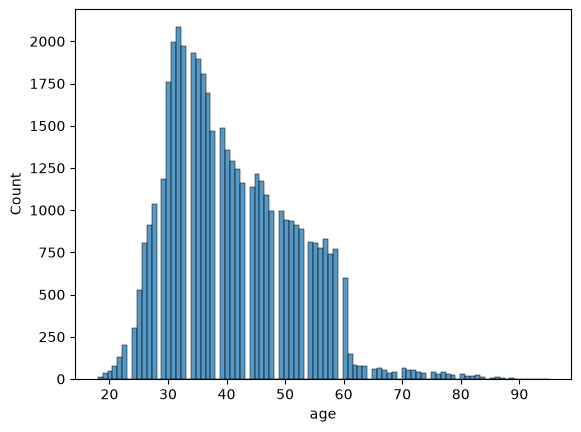

In [24]:
sns.histplot(X.age)

In [25]:
(X.balance >=0).value_counts()

balance
True     41445
False     3766
Name: count, dtype: int64

3766 clients have a negative average yearly balance. So it is not a data error.

In [26]:
X.campaign.value_counts(normalize=True)

campaign
1     0.388047
2     0.276592
3     0.122116
4     0.077901
5     0.039017
6     0.028555
7     0.016257
8     0.011944
9     0.007233
10    0.005884
11    0.004446
12    0.003428
13    0.002942
14    0.002057
15    0.001858
16    0.001747
17    0.001526
18    0.001128
19    0.000973
20    0.000951
21    0.000774
22    0.000509
25    0.000487
23    0.000487
24    0.000442
28    0.000354
29    0.000354
26    0.000288
31    0.000265
27    0.000221
32    0.000199
30    0.000177
33    0.000133
34    0.000111
35    0.000088
36    0.000088
43    0.000066
38    0.000066
41    0.000044
50    0.000044
37    0.000044
51    0.000022
63    0.000022
55    0.000022
46    0.000022
58    0.000022
39    0.000022
44    0.000022
Name: proportion, dtype: float64

<Axes: xlabel='campaign', ylabel='Count'>

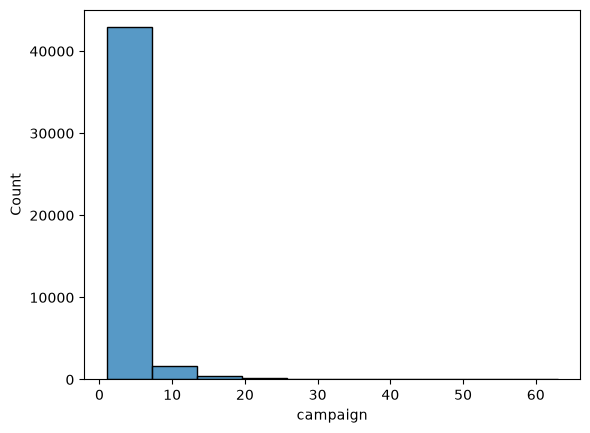

In [27]:
sns.histplot(X['campaign'],bins=10)

In [28]:
X.previous.value_counts(normalize=True)

previous
0      0.817367
1      0.061313
2      0.046582
3      0.025259
4      0.015793
5      0.010152
6      0.006127
7      0.004534
8      0.002853
9      0.002035
10     0.001482
11     0.001438
12     0.000973
13     0.000841
15     0.000442
14     0.000420
17     0.000332
16     0.000288
19     0.000243
20     0.000177
23     0.000177
18     0.000133
22     0.000133
27     0.000111
24     0.000111
21     0.000088
25     0.000088
29     0.000088
30     0.000066
26     0.000044
37     0.000044
38     0.000044
28     0.000044
51     0.000022
275    0.000022
58     0.000022
32     0.000022
40     0.000022
55     0.000022
35     0.000022
41     0.000022
Name: proportion, dtype: float64

In [29]:
X.pdays.value_counts(normalize=True)

pdays
-1      0.817367
 182    0.003694
 92     0.003251
 91     0.002787
 183    0.002787
          ...   
 541    0.000022
 543    0.000022
 871    0.000022
 550    0.000022
 530    0.000022
Name: proportion, Length: 559, dtype: float64

In [30]:
X['pdays'].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

-1 refers to clients not contacted before. But since this is a numerical value, -1 can give a wrong indication as the most recent/ future contact. It would be better to have a high number comparatively(999) and a separate column to show whether a client was contacted before or not.

In [31]:
X['contacted_before'] = (X['pdays']!=-1).astype(int)

In [32]:
X['pdays'] = X['pdays'].replace(-1, 999)

In [33]:
X.day_of_week.describe()

count    45211.000000
mean        15.806419
std          8.322476
min          1.000000
25%          8.000000
50%         16.000000
75%         21.000000
max         31.000000
Name: day_of_week, dtype: float64

In [34]:
X.rename(columns = {'day_of_week':'day_of_month'}, inplace=True)

In [35]:
categorical = ['job', 'marital', 'education', 'default', 'housing', 
               'loan', 'contact', 'month','poutcome', 'contacted_before']
numerical = ['age', 'balance', 'day_of_month', 'duration', 'campaign', 'pdays', 'previous']

In [36]:
X['convert'] = y

Splitting the dataset into train, val and test sets.

In [37]:
X_full_train, X_test = train_test_split(X, test_size = 0.2, random_state=1)
X_train, X_val = train_test_split(X_full_train, test_size = 0.25, random_state = 1)
X_full_train.shape, X_train.shape, X_val.shape, X_test.shape

((36168, 18), (27126, 18), (9042, 18), (9043, 18))

In [38]:
def mi_score(c):
    return(mutual_info_score(X_train.convert, c))

In [39]:
mi_scores = X_train[categorical].apply(mi_score)
mi_scores.sort_values(ascending=False)

poutcome            0.028586
month               0.024460
contact             0.012256
contacted_before    0.011219
housing             0.009158
job                 0.008130
loan                0.002538
education           0.002461
marital             0.002042
default             0.000453
dtype: float64

poutcome, month and contact variables have the stronger relation to the outcome then the remaining variables. default is the lowest impacting variable. 

In [40]:
def roc_auc(c):
    return roc_auc_score(X_train.convert, c)

In [41]:
auc_scores = X_train[numerical].apply(roc_auc)
auc_scores.sort_values(ascending=False)

duration        0.814700
previous        0.598565
balance         0.588831
age             0.487814
day_of_month    0.474042
campaign        0.428546
pdays           0.396090
dtype: float64

Duration has a very high impact on the outcome. This is very understandable given that interested clients tend to continue the conversations longer. The duration is known only after the call. As mentioned in the data description, duration of call is not known initially and should be dropped  for the prediction. So it is being dropped from the numerical list.

In [42]:
numerical = ['age', 'balance', 'day_of_month', 'campaign', 'pdays', 'previous']

AUC for age, day_of_month, campaign and pdays is < 0.5 which means a negative relation. So the AUC scores should be flipped.

pdays: lowest because the previously not contacted have been given 999 as the value. So previously contacted clients tend to convert.
campaign: clients contacted more times in the current campaign tend to convert less.
higher blanace and previously contacted clients tend to convert more.

In [43]:
auc_scores = []
for n in numerical:

    if roc_auc_score(X_train.convert, X_train[n]) >= 0.5:
        auc_scores.append((n, roc_auc_score(X_train.convert, X_train[n])))
    else: 
        auc_scores.append((n, roc_auc_score(X_train.convert, -X_train[n])))

print(auc_scores)        

[('age', 0.512185717527344), ('balance', 0.5888313805382317), ('day_of_month', 0.525957882383908), ('campaign', 0.5714543015682159), ('pdays', 0.603909718327218), ('previous', 0.5985653242764153)]


In [44]:
auc_scores

[('age', 0.512185717527344),
 ('balance', 0.5888313805382317),
 ('day_of_month', 0.525957882383908),
 ('campaign', 0.5714543015682159),
 ('pdays', 0.603909718327218),
 ('previous', 0.5985653242764153)]

*pdays, previous and balance* have the highest relation to the target and *day_of_month, age* have the least.

In [45]:
X_train[numerical].corr()

,age,balance,day_of_month,campaign,pdays,previous
age,1.000000,0.107200,-0.009160,0.004503,-0.005512,-0.001814
balance,0.107200,1.000000,0.003456,-0.015384,-0.037578,0.022400
day_of_month,-0.009160,0.003456,1.000000,0.164946,0.072462,-0.052384
campaign,0.004503,-0.015384,0.164946,1.000000,0.107337,-0.042301
pdays,-0.005512,-0.037578,0.072462,0.107337,1.000000,-0.637478
previous,-0.001814,0.022400,-0.052384,-0.042301,-0.637478,1.000000


The only relation that is being highlighted is between *pdays* and *previous* with -0.64. The negative relation could be the result of changing not contacted clients (previous = 0) to pdays = 999.

We need to calculate the conversion rate for each category of the categorical variables and compare it to the overall conversion rate.

In [47]:
#Conversion Rate for X_train:
train_conv = X_train.convert.mean()
train_conv

0.11579296615792967

In [48]:
print(f'The conversion rate for X_train is similar to the overall rate: {global_conv.round(3)}')

The conversion rate for X_train is similar to the overall rate: 0.117


In [49]:
for c in categorical:

    df_group = X_train.groupby(c).convert.agg(['count','mean'])
    df_group['diff'] = df_group['mean'] - train_conv
    df_group['chance'] = df_group['mean'] / train_conv
    print(c)
    print(df_group)
    print()
    print()

job
               count      mean      diff    chance
job                                               
NA               174  0.114943 -0.000850  0.992656
admin.          3180  0.117610  0.001817  1.015693
blue-collar     5865  0.073998 -0.041795  0.639057
entrepreneur     906  0.091611 -0.024181  0.791166
housemaid        747  0.093708 -0.022085  0.809273
management      5613  0.136469  0.020676  1.178560
retired         1332  0.224474  0.108682  1.938585
self-employed    920  0.123913  0.008120  1.070126
services        2537  0.090264 -0.025529  0.779530
student          560  0.298214  0.182421  2.575409
technician      4518  0.102700 -0.013093  0.886930
unemployed       774  0.156331  0.040538  1.350088


marital
          count      mean      diff    chance
marital                                      
divorced   3187  0.113586 -0.002207  0.980944
married   16261  0.100855 -0.014938  0.870993
single     7678  0.148346  0.032553  1.281131


education
           count      mean    

There are some interesting insights here:
- In job category, *students* tend to convert 2.5x more than the average and *retired* people covert 1.9x. These are the 2 categories who are not earning a full time salary.
- The clients defaulted have a convert lower, 0.45x the average and the non defaulted clients have the same rate as the average.
- The last contact month have a significant variation: *mar, oct, sep, dec* have high conversion rates. This could also be because the count is significantly lower during these months.
- The category with the most impact is the poutcome. successful poutcome has 0.65 conversion rate which is 5.6x the average. This variable seems to play a significant role in prediction.

Logistic Regression Model Training

In [108]:
def train(df_train, y_train, C):

    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train,y_train)

    return dv, model

In [109]:
def predict(df, dv, model):

    dicts = df[categorical+numerical].to_dict(orient='records')
    
    X = dv.transform(dicts)
    
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [110]:
y_train = X_train.convert.values
y_val = X_val.convert.values

dv, model = train(X_train, y_train, C=1.0)
y_pred = predict(X_val, dv, model)

AUC_baseline = roc_auc_score(y_val, y_pred)
AUC_baseline

0.7749263056330562

AUC score of 0.775 is a pretty good score. We can try to improve it by experimenting with the features.

In [83]:
features = categorical + numerical
auc_scores = []

for f in features:
    feature_updated = features.copy()
    feature_updated.remove(f)

    dicts = X_train[feature_updated].to_dict(orient='records')
    dv = DictVectorizer(sparse = False)
    X_tr = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    y_tr = X_train.convert.values
    model.fit(X_tr,y_tr)
    
    dicts = X_val[feature_updated].to_dict(orient='records')
    X_va = dv.transform(dicts)
    
    y_pred = model.predict_proba(X_va)[:,1]
    y_va = X_val.convert.values
    auc_feat = roc_auc_score(y_va, y_pred)
    auc_scores.append((f, auc_feat, AUC-auc_feat))

df_auc = pd.DataFrame(auc_scores, columns=['features', 'auc_score', 'diff'])

In [84]:
df_auc.sort_values('auc_score', ascending=False)

,features,auc_score,diff
9,job,0.775672,-0.000746
12,day_of_month,0.775602,-0.000675
8,contacted_before,0.775588,-0.000662
10,age,0.775555,-0.000629
2,default,0.775307,-0.000381
14,pdays,0.774997,-0.000070
1,education,0.774955,-0.000029
4,loan,0.774338,0.000588
11,balance,0.774085,0.000841
15,previous,0.773746,0.001181


We can see the change in AUC score when a single feature is excluded. The features which have diff<0 can be removed from the model as this shows a better AUC score.

In [100]:
features_updated = list(df_auc[df_auc['diff']>0]['features'].values)
features_updated

['marital',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome',
 'balance',
 'campaign',
 'previous']

In [101]:
def train_updated(df_train, y_train, C=1.0):

    dicts = df_train[features_updated].to_dict(orient='records')
    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train,y_train)

    return dv, model

In [102]:
def predict_updated(df, dv, model):

    dicts = df[features_updated].to_dict(orient='records')
    
    X = dv.transform(dicts)
    
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [105]:
y_train = X_train.convert.values
y_val = X_val.convert.values

dv, model = train_updated(X_train, y_train, C=1.0)
y_pred = predict_updated(X_val, dv, model)

AUC_features_updated = roc_auc_score(y_val, y_pred)
AUC_features_updated

0.7722830877160157

In [106]:
AUC_baseline - AUC_features_updated

0.0026432179170404746

By removing individual features, maximum improvment in AUC score is 0.000746 and by removing 7 features together reduced the AUC by 0.00264. So removing each or all the 7 features don't have a huge improvement on the model, we can keep all the features.

Now let's try out multiple C values among [0.001, 0.01, 0.1, 0.5, 1, 5, 10] to see which gives the best model. We use the KFold to do 5-fold validation to get the best C value.

In [114]:
kfold = KFold(n_splits=5, shuffle= True, random_state=1)

for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    scores = []
    for train_idx, val_idx in kfold.split(X_full_train):
        df_tr = X_full_train.iloc[train_idx]
        df_va = X_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr.convert.values, C)
        y_pred = predict(df_va, dv, model)

        auc_score = roc_auc_score(df_va.convert.values, y_pred)
        scores.append(auc_score)

    print(f'C={C}, Mean AUC={np.mean(scores)}, STD={np.std(scores)}')
    

C=0.001, Mean AUC=0.7244895708508823, STD=0.0070794974698016955
C=0.01, Mean AUC=0.758761361316383, STD=0.007113905659853125
C=0.1, Mean AUC=0.7637852898294689, STD=0.007588879685730229
C=0.5, Mean AUC=0.7636311599824692, STD=0.007610691244494001
C=1, Mean AUC=0.7634095963958425, STD=0.007404473598275485
C=5, Mean AUC=0.7632904627342482, STD=0.007590329739274112
C=10, Mean AUC=0.7625811247405444, STD=0.008258288110140106


The mean AUC varies very less from C=0.1 to C=5. C=0.1 has the best AUC mean and is chosen to be used for training the final model.

In [115]:
y_full_train = X_full_train.convert.values
y_test = X_test.convert.values

dv, model = train(X_full_train, y_full_train, C=0.1)
y_pred = predict(X_test, dv, model)

AUC_c = roc_auc_score(y_test, y_pred)
AUC_c

0.7743044211303938

The final logistic regression model with C=0.1 gives an AUC of 0.774 which is consistent with the 5-Fold validation AUC(0.764) and the baseline AUC(0.775).